# Détection de faux billets

L’objectif de ce projet est de créer un modèle permettant d’identifier des faux billets à partir de leurs dimensions.

## Importation des librairies

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import joblib

## Importation et exploration du jeu de données

In [2]:
billets = pd.read_csv('billets.csv', sep=';')

In [3]:
billets.describe()

,diagonal,height_left,height_right,margin_low,margin_up,length
count,1500.000000,1500.000000,1500.000000,1463.000000,1500.000000,1500.00000
mean,171.958440,104.029533,103.920307,4.485967,3.151473,112.67850
std,0.305195,0.299462,0.325627,0.663813,0.231813,0.87273
min,171.040000,103.140000,102.820000,2.980000,2.270000,109.49000
25%,171.750000,103.820000,103.710000,4.015000,2.990000,112.03000
50%,171.960000,104.040000,103.920000,4.310000,3.140000,112.96000
75%,172.170000,104.230000,104.150000,4.870000,3.310000,113.34000
max,173.010000,104.880000,104.950000,6.900000,3.910000,114.44000


In [4]:
billets.head()

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54


In [5]:
billets.isna().sum()

is_genuine       0
diagonal         0
height_left      0
height_right     0
margin_low      37
margin_up        0
length           0
dtype: int64

On voit qu’il y a 37 données manquantes pour margin_low.

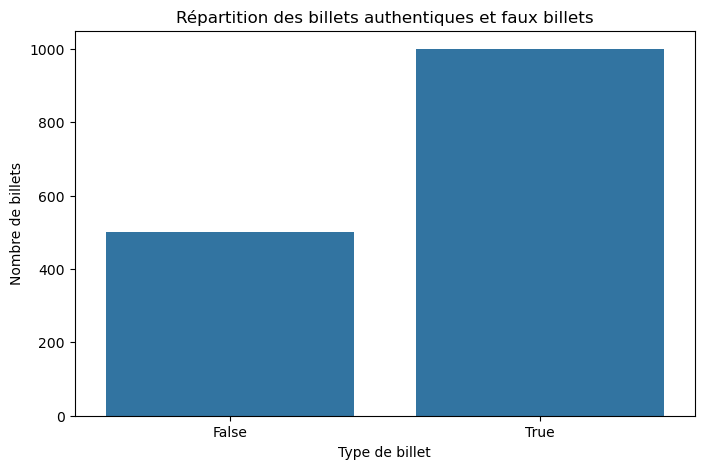

In [6]:
# histogramme de la variable cible
plt.figure(figsize=(8, 5))
sns.countplot(x='is_genuine', data=billets)
plt.title('Répartition des billets authentiques et faux billets')
plt.xlabel('Type de billet')
plt.ylabel('Nombre de billets')
plt.show()

Nous ne sommes pas dans une situation de données déséquilibrées.

## Imputation des valeurs manquantes par régression

In [7]:
df_num = billets.select_dtypes(include=[np.number])
target = "margin_low"  

df_train = df_num[df_num[target].notna()]
df_pred  = df_num[df_num[target].isna()]

X_train = df_train.drop(columns=target)
y_train = df_train[target]

X_pred = df_pred.drop(columns=target)

lr = LinearRegression()
lr.fit(X_train, y_train)

billets.loc[billets[target].isna(), target] = lr.predict(X_pred)

In [8]:
billets.isna().sum()

is_genuine      0
diagonal        0
height_left     0
height_right    0
margin_low      0
margin_up       0
length          0
dtype: int64

Les valeurs manquantes ont bien été imputées.

## Création du modèle de détection de faux billets 

Nous allons créer 3 algorithmes, étudier leurs performances et conserver le meilleur.

### SVM

In [9]:
X = billets.drop(columns="is_genuine")
y = billets["is_genuine"]

pipe_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", probability=True, random_state=42))
])

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_results = cross_validate(
    pipe_svm,
    X,
    y,
    cv=cv,
    scoring=scoring,
    return_train_score=False
)

for metric in cv_results:
    if "test" in metric:
        scores = cv_results[metric]
        print(f"{metric} : {scores.mean():.3f} ± {scores.std():.3f}")

test_accuracy : 0.991 ± 0.007
test_precision : 0.990 ± 0.010
test_recall : 0.997 ± 0.005
test_f1 : 0.994 ± 0.005


### Forêt aléatoire 

In [11]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

cv_10 = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_rf = cross_validate(
    rf,
    X,
    y,
    cv=cv_10,
    scoring=scoring,
    return_train_score=False
)

for metric in cv_rf:
    if "test" in metric:
        scores = cv_rf[metric]
        print(f"{metric} : {scores.mean():.3f} ± {scores.std():.3f}")

test_accuracy : 0.991 ± 0.009
test_precision : 0.990 ± 0.010
test_recall : 0.996 ± 0.007
test_f1 : 0.993 ± 0.007


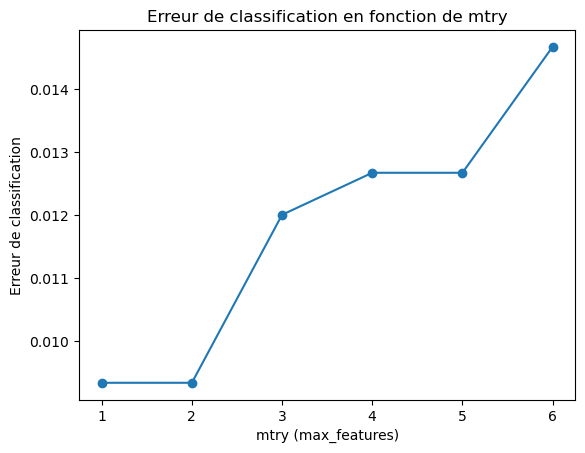

In [ ]:
# Séparation X / y
X = billets.drop(columns="is_genuine")
y = billets["is_genuine"]

# Nombre de variables
n_features = X.shape[1]

# Valeurs de mtry testées
mtry_values = range(1, n_features + 1)
errors = []

# Validation croisée 10 blocs
cv_10 = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Boucle sur mtry
for mtry in mtry_values:
    rf = RandomForestClassifier(
        n_estimators=300,
        max_features=mtry,
        random_state=42
    )

    scores = cross_val_score(
        rf,
        X,
        y,
        cv=cv_10,
        scoring="accuracy"
    )

    errors.append(1 - scores.mean())

# Graphique
plt.figure()
plt.plot(mtry_values, errors, marker='o')
plt.xlabel("mtry (max_features)")
plt.ylabel("Erreur de classification")
plt.title("Erreur de classification en fonction de mtry")
plt.show()


Il peut ici choisir 2 features pour minimiser l’erreur. On refait tourner la forêt avec ce paramètre.

In [13]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    max_features=2
)

cv_10 = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_rf = cross_validate(
    rf,
    X,
    y,
    cv=cv_10,
    scoring=scoring,
    return_train_score=False
)

for metric in cv_rf:
    if "test" in metric:
        scores = cv_rf[metric]
        print(f"{metric} : {scores.mean():.3f} ± {scores.std():.3f}")

test_accuracy : 0.991 ± 0.009
test_precision : 0.990 ± 0.010
test_recall : 0.996 ± 0.007
test_f1 : 0.993 ± 0.007


### Gradient boosting

In [ ]:
gb = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

cv_10 = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_gb = cross_validate(
    gb,
    X,
    y,
    cv=cv_10,
    scoring=scoring,
    return_train_score=False
)

for metric in cv_gb:
    if "test" in metric:
        scores = cv_gb[metric]
        print(f"{metric} : {scores.mean():.3f} ± {scores.std():.3f}")

test_accuracy : 0.989 ± 0.011
test_precision : 0.990 ± 0.009
test_recall : 0.994 ± 0.009
test_f1 : 0.992 ± 0.008


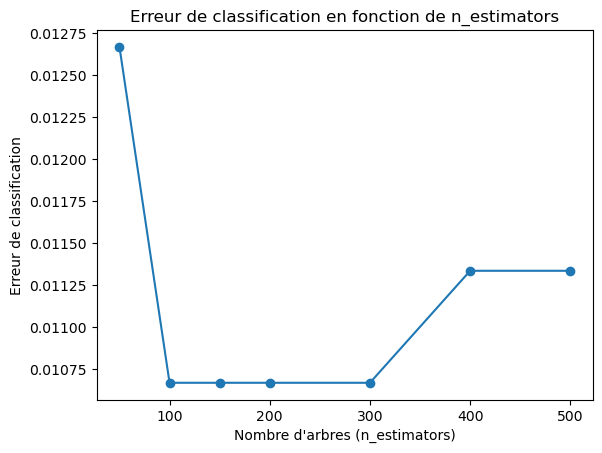

In [ ]:
# Valeurs testées
n_estimators_values = [50, 100, 150, 200, 300, 400, 500]
errors = []

cv_10 = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

for n in n_estimators_values:
    gb = GradientBoostingClassifier(
        n_estimators=n,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )

    scores = cross_val_score(
        gb,
        X,
        y,
        cv=cv_10,
        scoring="accuracy"
    )

    errors.append(1 - scores.mean())

# Graphique
plt.figure()
plt.plot(n_estimators_values, errors, marker='o')
plt.xlabel("Nombre d'arbres (n_estimators)")
plt.ylabel("Erreur de classification")
plt.title("Erreur de classification en fonction de n_estimators")
plt.show()


Le choix de 200 arbres était cohérent.

## Choix de la méthode 

| Modèle              | Accuracy (± std) | Precision (± std) | Recall (± std) | F1-score (± std) |
|---------------------|------------------|-------------------|----------------|------------------|
| SVM                 | 0.991 ± 0.007    | 0.990 ± 0.010     | 0.997 ± 0.005  | 0.994 ± 0.005    |
| Random Forest       | 0.991 ± 0.009    | 0.990 ± 0.010     | 0.996 ± 0.007  | 0.993 ± 0.007    |
| Gradient Boosting   | 0.989 ± 0.011    | 0.990 ± 0.009     | 0.994 ± 0.009  | 0.992 ± 0.008    |


Les trois modèles présentent des performances élevées et stables.  
Le SVM obtient les meilleurs résultats globaux, notamment en termes de F1-score et de rappel, indiquant une excellente capacité de généralisation.  
La Random Forest offre des performances comparables, tandis que le Gradient Boosting reste légèrement en retrait mais demeure très performant.


## Interprétation concrète des indicateurs de performance du SVM

Les indicateurs de performance permettent de comprendre concrètement le comportement du modèle.

#### Accuracy
L’accuracy correspond à la proportion totale de billets correctement classés.

**Exemple concret :**  
Si l’on teste le modèle sur 1 000 billets et que l’accuracy est de 0,991, cela signifie qu’environ **991 billets sont correctement classés** et **9 billets sont mal classés**, toutes catégories confondues.

Cette métrique donne une vision globale des performances, mais ne permet pas à elle seule d’identifier le type d’erreurs commises.

---

#### Precision
La précision mesure la fiabilité des prédictions positives du modèle.

**Exemple concret :**  
Si le modèle prédit qu’un billet est authentique 100 fois et que la précision est de 0,99, alors **99 de ces billets sont réellement authentiques** et **1 billet est en réalité faux**.

Une précision élevée est importante lorsque l’on souhaite **éviter d’accepter des faux billets**.

---

#### Recall
Le recall mesure la capacité du modèle à détecter l’ensemble des billets authentiques.

**Exemple concret :**  
Si 1 000 billets sont réellement authentiques et que le recall est de 0,997, alors le modèle **identifie correctement 997 billets authentiques**, mais **en manque 3**, qui sont classés à tort comme faux.

Un recall élevé est crucial lorsque l’on souhaite **minimiser le nombre de billets authentiques rejetés à tort**.

---

#### F1-score
Le F1-score combine la précision et le recall en une seule mesure.

**Exemple concret :**  
Un F1-score de 0,994 indique que le modèle présente un **excellent équilibre** entre :
- la fiabilité de ses prédictions (précision),
- sa capacité à détecter correctement les billets authentiques (recall).

---

#### Écart-type (±)
L’écart-type indique la stabilité des performances du modèle lors de la validation croisée.

**Exemple concret :**  
Un F1-score de 0,994 ± 0,005 signifie que, selon le sous-ensemble de données utilisé pour l’entraînement et le test, le score F1 varie très peu (entre environ 0,989 et 0,999).

Un faible écart-type montre que le modèle est **robuste** et **généralise bien**, indépendamment du découpage du jeu de données.


## Sauvegarde du SVM

In [ ]:
pipe_svm.fit(X, y)

joblib.dump(pipe_svm, "svm_billets_model.pkl")

['svm_billets_model.pkl']